# Project1: Social Network Analyzer

Goal: A complete scocial network analysis pipeline on a realistic small network. Produce a standrd report

In [1]:
import networkx as nx
SOCIAL = nx.Graph()

people_data = [
    ("Alice",   {"role": "CEO",       "dept": "Exec"}),
    ("Bob",     {"role": "CTO",       "dept": "Tech"}),
    ("Carol",   {"role": "Engineer",  "dept": "Tech"}),
    ("David",   {"role": "Engineer",  "dept": "Tech"}),
    ("Eve",     {"role": "Designer",  "dept": "Product"}),
    ("Frank",   {"role": "PM",        "dept": "Product"}),
    ("Grace",   {"role": "CMO",       "dept": "Marketing"}),
    ("Heidi",   {"role": "Analyst",   "dept": "Marketing"}),
    ("Ivan",    {"role": "CFO",       "dept": "Finance"}),
    ("Judy",    {"role": "Accountant","dept": "Finance"}),
    ("Kevin",   {"role": "Consultant","dept": "External"}),
    ("Laura",   {"role": "Advisor",   "dept": "External"}),
]
SOCIAL.add_nodes_from(people_data)

connections = [
    ("Alice",  "Bob"),    ("Alice",  "Grace"),  ("Alice",  "Ivan"),
    ("Alice",  "Frank"),  ("Alice",  "Kevin"),  ("Alice",  "Laura"),
    ("Bob",    "Carol"),  ("Bob",    "David"),  ("Bob",    "Eve"),
    ("Bob",    "Frank"),
    ("Carol",  "David"),
    ("Eve",    "Frank"),  ("Eve",    "Grace"),
    ("Grace",  "Heidi"),  ("Grace",  "Frank"),
    ("Ivan",   "Judy"),   ("Ivan",   "Alice"),
    ("Kevin",  "Laura"),  ("Kevin",  "Bob"),
]
SOCIAL.add_edges_from(connections)

## Basic Facts

In [2]:
print("=" * 65)
print("PROJECT 1 — SOCIAL NETWORK ANALYSIS REPORT")
print("=" * 65)

# Section 1: Basic facts
print("\n── 1. STRUCTURAL OVERVIEW ──")
print(f"  People (nodes)     : {SOCIAL.number_of_nodes()}")
print(f"  Connections (edges): {SOCIAL.number_of_edges()}")
print(f"  Density            : {nx.density(SOCIAL):.4f}")
avg_deg = sum(d for _, d in SOCIAL.degree()) / SOCIAL.number_of_nodes()
print(f"  Average degree     : {avg_deg:.2f} connections per person")
print(f"  Is connected       : {nx.is_connected(SOCIAL)}")
if nx.is_connected(SOCIAL):
    print(f"  Diameter           : {nx.diameter(SOCIAL)} hops")
    print(f"  Avg path length    : {nx.average_shortest_path_length(SOCIAL):.3f} hops")

PROJECT 1 — SOCIAL NETWORK ANALYSIS REPORT

── 1. STRUCTURAL OVERVIEW ──
  People (nodes)     : 12
  Connections (edges): 18
  Density            : 0.2727
  Average degree     : 3.00 connections per person
  Is connected       : True
  Diameter           : 4 hops
  Avg path length    : 2.167 hops


## Centrality

In [3]:
# Section 2: Centrality
print("\n── 2. CENTRALITY RANKINGS ──")
deg_c  = nx.degree_centrality(SOCIAL)
bet_c  = nx.betweenness_centrality(SOCIAL)
clo_c  = nx.closeness_centrality(SOCIAL)
pr     = nx.pagerank(SOCIAL, alpha=0.85)

print(f"  {'Name':10s}  {'Degree':8s}  {'Betwn':8s}  {'Close':8s}  {'PageRank':10s}  Role")
print("  " + "-" * 65)
for node in sorted(SOCIAL.nodes(), key=lambda n: -deg_c[n]):
    role = SOCIAL.nodes[node].get("role", "?")
    print(
        f"  {node:10s}  {deg_c[node]:8.3f}  {bet_c[node]:8.3f}  "
        f"{clo_c[node]:8.3f}  {pr[node]:10.4f}  {role}")


── 2. CENTRALITY RANKINGS ──
  Name        Degree    Betwn     Close     PageRank    Role
  -----------------------------------------------------------------
  Alice          0.545     0.505     0.688      0.1557  CEO
  Bob            0.545     0.382     0.611      0.1513  CTO
  Frank          0.364     0.059     0.579      0.1013  PM
  Grace          0.364     0.205     0.524      0.1086  CMO
  Eve            0.273     0.036     0.478      0.0785  Designer
  Kevin          0.273     0.032     0.524      0.0804  Consultant
  Carol          0.182     0.000     0.407      0.0590  Engineer
  David          0.182     0.000     0.407      0.0590  Engineer
  Ivan           0.182     0.182     0.458      0.0707  CFO
  Laura          0.182     0.000     0.440      0.0573  Advisor
  Heidi          0.091     0.000     0.355      0.0356  Analyst
  Judy           0.091     0.000     0.324      0.0426  Accountant


## Clustering

In [4]:
from networkx.algorithms.community import greedy_modularity_communities, modularity
# Section 3: Clustering
print("\n── 3. CLUSTERING ──")
print(f"  Average clustering coefficient: {nx.average_clustering(SOCIAL):.4f}")
print(f"  Transitivity (global)         : {nx.transitivity(SOCIAL):.4f}")

# Section 4: Communities
comms = list(greedy_modularity_communities(SOCIAL))
Q     = modularity(SOCIAL, comms)
print("\n── 4. COMMUNITIES ──")
print(f"  Communities found: {len(comms)}  |  Modularity Q: {Q:.4f}")
for i, comm in enumerate(comms, 1):
    depts = set(SOCIAL.nodes[n].get("dept", "?") for n in comm)
    print(f"  Community {i}: {sorted(comm)}  →  departments: {depts}")

# Section 5: Vulnerabilities
art = sorted(nx.articulation_points(SOCIAL))
brs = sorted(nx.bridges(SOCIAL))
print("\n── 5. STRUCTURAL VULNERABILITIES ──")
print(f"  Articulation points: {art}")
print(f"  Bridges            : {brs}")



── 3. CLUSTERING ──
  Average clustering coefficient: 0.4889
  Transitivity (global)         : 0.4038

── 4. COMMUNITIES ──
  Communities found: 3  |  Modularity Q: 0.3272
  Community 1: ['Alice', 'Ivan', 'Judy', 'Kevin', 'Laura']  →  departments: {'External', 'Exec', 'Finance'}
  Community 2: ['Eve', 'Frank', 'Grace', 'Heidi']  →  departments: {'Marketing', 'Product'}
  Community 3: ['Bob', 'Carol', 'David']  →  departments: {'Tech'}

── 5. STRUCTURAL VULNERABILITIES ──
  Articulation points: ['Alice', 'Bob', 'Grace', 'Ivan']
  Bridges            : [('Alice', 'Ivan'), ('Grace', 'Heidi'), ('Ivan', 'Judy')]


## Visualization

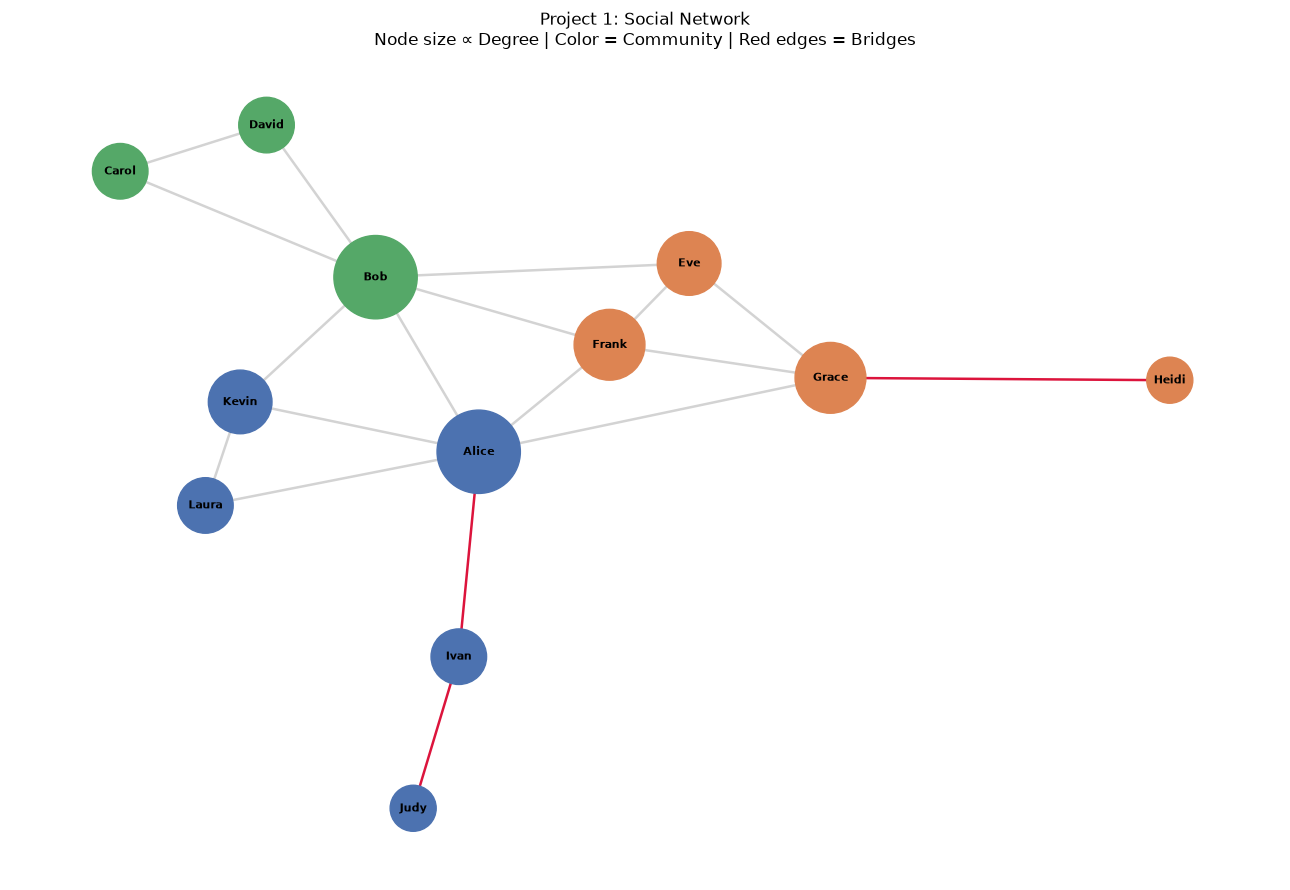

In [5]:
import matplotlib.pyplot as plt
# ─────────────────────────────────────────────────────────────────────
# Final Visualization
# ─────────────────────────────────────────────────────────────────────
plt.figure(figsize=(13, 9))
pos = nx.spring_layout(SOCIAL, seed=42)

palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
color_map = {}
for i, comm in enumerate(comms):
    for node in comm:
        color_map[node] = palette[i % len(palette)]

node_sizes = [500 + 600 * bet_c[n] * 15 for n in SOCIAL.nodes()]
colors = [color_map[n] for n in SOCIAL.nodes()]
ec = ["crimson" if e in brs or (e[1], e[0]) in brs else "lightgray"
      for e in SOCIAL.edges()]

nx.draw_networkx(SOCIAL, pos,
                 node_color=colors,
                 node_size=[600 + 500 * SOCIAL.degree(n) for n in SOCIAL.nodes()],
                 edge_color=ec,
                 font_size=8,
                 font_weight="bold",
                 width=1.8)

plt.title("Project 1: Social Network\nNode size ∝ Degree | Color = Community | Red edges = Bridges",
          fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()
